# Final diagnostic 02 — count-preserving Binding swaps

**Full design:** two Constant-LR curricula (`mixed`, `prereq_mixed_pair_focus`) × five seeds (42–46) × three checkpoints (5,400; 7,200; 9,000) = **30 frozen checkpoints**. Validate every checkpoint SHA-256 and the source dataset hashes before computing any result. No ViT retraining. Resumes verified per-run CSV files and never overwrites the pilot outputs.

Swap editing changes Color–Shape association while keeping object counts, Color and Shape multisets, positions and sizes fixed. Report both-correct and correct-probability direction, each **separated and balanced** by the original Yes/No label. This controls target multiplicity, not all scene cues. Statistical unit is a paired seed (n=5), not 109 independent experiments.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path().cwd().resolve().parent.parent
if str(PROJECT_ROOT) not in sys.path: 
    sys.path.insert(0, str(PROJECT_ROOT))
import pandas as pd
import numpy as np
import torch
from src.medium_visual_world.diagnostic_followup import (
    load_jsonl, count_free, locate_checkpoint, load_frozen_model,
    run_swaps, extract_object_crops, shape_object_probes,
    scene_shape_head_probe, make_swap
)
from src.medium_visual_world.final_diagnostic_followup import (
    SCHEDULES, SEEDS, STEPS, experiment_grid, experiment_tag,
    validate_manifest, validate_frozen_datasets, verified_sha,
    ensure_run_file, atomic_csv, paired_checkpoint_differences,
    swap_metrics, mean_ci, task_head_competition_controlled
)
from src.medium_visual_world.learning import MediumDataset, AttributeBindingViT, set_seed
OUTPUT = PROJECT_ROOT / "outputs/medium_world/experiments/diagnostic_followup/final_five_seeds"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MANIFEST = validate_manifest(PROJECT_ROOT)   # require the original 30 checkpoints and correct hashes
HASHES = validate_frozen_datasets(PROJECT_ROOT)
print("Validated 30 checkpoints, frozen data hashes, device:", DEVICE)

Validated 30 checkpoints, frozen data hashes, device: cuda


In [ ]:
rows = load_jsonl(PROJECT_ROOT / "outputs/medium_world/dataset/id_dev.jsonl")
eligible = [r for r in rows if make_swap(r) is not None]
expected_ids = {str(r["id"]) for r in eligible}
source_labels = {str(r["id"]): int(r["label"]) for r in eligible}
if len(eligible) != 109 or len(expected_ids) != len(eligible):
    raise AssertionError("Frozen count-controlled swap support changed (expected 109 unique questions)")
folder = OUTPUT / "binding_swaps"
folder.mkdir(parents=True, exist_ok=True)
raw_parts = []
for schedule, seed, step in experiment_grid():
    run_name = experiment_tag(schedule,seed,step)
    checkpoint = locate_checkpoint(PROJECT_ROOT,schedule,seed,step,MANIFEST)
    sha = verified_sha(PROJECT_ROOT,schedule,seed,step,MANIFEST)
    target = folder / f"swap_{run_name}.csv"
    cached = ensure_run_file(target,
        ("example_id","checkpoint_sha256","both_correct","correct_direction","label_before","label_after"),
        {"schedule":schedule,"seed":seed,"step":step,"checkpoint_sha256":sha},n=len(eligible))
    if cached is None:
        model,_ = load_frozen_model(checkpoint,DEVICE)
        part = run_swaps(model,rows,DEVICE)
        part.insert(0,"schedule",schedule)
        part.insert(1,"seed",seed)
        part.insert(2,"step",step)
        part["checkpoint_sha256"] = sha
        atomic_csv(part,target)
        del model
        print("COMPUTED",run_name)
    else:
        part=cached
        print("VERIFIED",run_name)
    if len(part)!=109 or set(part.example_id.astype(str))!=expected_ids or part.example_id.duplicated().any():
        raise AssertionError(f"Incorrect swap IDs/support: {run_name}")
    if any(int(r.label_before) != source_labels[str(r.example_id)] for r in part.itertuples()):
        raise AssertionError(f"Cached/original swap labels differ: {run_name}")
    raw_parts.append(part)
raw = pd.concat(raw_parts,ignore_index=True)
summary = pd.DataFrame([dict(schedule=s,seed=seed,step=step,**swap_metrics(g))
         for (s,seed,step),g in raw.groupby(["schedule","seed","step"],sort=False)])
atomic_csv(summary, folder/"swap_summary_30_runs.csv")
compare = paired_checkpoint_differences(summary,
    ["both_correct","correct_direction","balanced_both_correct","balanced_direction",
     "before_accuracy","after_accuracy","mean_signed_delta"])
atomic_csv(compare, folder/"swap_five_seed_contrasts.csv")
print("All 30 swaps completed, each with",len(eligible),"original questions")
display(summary.round(4))
display(compare.round(4))

COMPUTED mixed_seed42_step5400
COMPUTED mixed_seed42_step7200
COMPUTED mixed_seed42_step9000
COMPUTED mixed_seed43_step5400
COMPUTED mixed_seed43_step7200
COMPUTED mixed_seed43_step9000
COMPUTED mixed_seed44_step5400
COMPUTED mixed_seed44_step7200
COMPUTED mixed_seed44_step9000
COMPUTED mixed_seed45_step5400
COMPUTED mixed_seed45_step7200
COMPUTED mixed_seed45_step9000
COMPUTED mixed_seed46_step5400
COMPUTED mixed_seed46_step7200
COMPUTED mixed_seed46_step9000
COMPUTED prereq_mixed_pair_focus_seed42_step5400
COMPUTED prereq_mixed_pair_focus_seed42_step7200
COMPUTED prereq_mixed_pair_focus_seed42_step9000
COMPUTED prereq_mixed_pair_focus_seed43_step5400
COMPUTED prereq_mixed_pair_focus_seed43_step7200
COMPUTED prereq_mixed_pair_focus_seed43_step9000
COMPUTED prereq_mixed_pair_focus_seed44_step5400
COMPUTED prereq_mixed_pair_focus_seed44_step7200
COMPUTED prereq_mixed_pair_focus_seed44_step9000
COMPUTED prereq_mixed_pair_focus_seed45_step5400
COMPUTED prereq_mixed_pair_focus_seed45_step7

,schedule,seed,step,n,n_before_no,n_before_yes,both_correct,correct_direction,before_accuracy,after_accuracy,...,both_before_no,direction_before_no,before_accuracy_before_no,after_accuracy_before_no,both_before_yes,direction_before_yes,before_accuracy_before_yes,after_accuracy_before_yes,balanced_both_correct,balanced_direction
0,mixed,42,5400,109,75,34,0.2110,0.6422,0.5046,0.6147,...,0.2267,0.6533,0.4267,0.7200,0.1765,0.6176,0.6765,0.3824,0.2016,0.6355
1,mixed,42,7200,109,75,34,0.2936,0.6789,0.5872,0.6514,...,0.3067,0.6800,0.4933,0.7467,0.2647,0.6765,0.7941,0.4412,0.2857,0.6782
2,mixed,42,9000,109,75,34,0.3578,0.7523,0.6055,0.7064,...,0.3867,0.7333,0.5200,0.8000,0.2941,0.7941,0.7941,0.5000,0.3404,0.7637
3,mixed,43,5400,109,75,34,0.2202,0.5780,0.5321,0.6055,...,0.2267,0.5733,0.5333,0.6267,0.2059,0.5882,0.5294,0.5588,0.2163,0.5808
4,mixed,43,7200,109,75,34,0.2569,0.6147,0.5596,0.6239,...,0.2800,0.6267,0.5600,0.6667,0.2059,0.5882,0.5588,0.5294,0.2429,0.6075
5,mixed,43,9000,109,75,34,0.2477,0.6881,0.5321,0.6514,...,0.2667,0.6933,0.4533,0.7733,0.2059,0.6765,0.7059,0.3824,0.2363,0.6849
6,mixed,44,5400,109,75,34,0.2569,0.4862,0.4862,0.6330,...,0.2800,0.5333,0.3600,0.7867,0.2059,0.3824,0.7647,0.2941,0.2429,0.4578
7,mixed,44,7200,109,75,34,0.1743,0.5413,0.4220,0.7156,...,0.1867,0.5733,0.1867,0.9600,0.1471,0.4706,0.9412,0.1765,0.1669,0.5220
8,mixed,44,9000,109,75,34,0.2477,0.6697,0.5046,0.6697,...,0.2800,0.7067,0.3333,0.8533,0.1765,0.5882,0.8824,0.2647,0.2282,0.6475
9,mixed,45,5400,109,75,34,0.2661,0.6422,0.6147,0.5138,...,0.2933,0.6400,0.6400,0.4933,0.2059,0.6471,0.5588,0.5588,0.2496,0.6435


,metric,contrast,n_seeds,mean,sd,ci95_low,ci95_high,positive_seeds
0,both_correct,mixed: 5400 to 7200,5,0.0349,0.0738,-0.0568,0.1265,4
1,both_correct,mixed: 7200 to 9000,5,0.0220,0.0433,-0.0318,0.0758,2
2,both_correct,mixed: 5400 to 9000,5,0.0569,0.0620,-0.0201,0.1339,4
3,both_correct,prereq_mixed_pair_focus: 5400 to 7200,5,0.3505,0.0766,0.2554,0.4456,5
4,both_correct,prereq_mixed_pair_focus: 7200 to 9000,5,-0.0679,0.0370,-0.1139,-0.0219,0
...,...,...,...,...,...,...,...,...
58,mean_signed_delta,prereq_mixed_pair_focus: 7200 to 9000,5,-0.0404,0.0508,-0.1035,0.0227,1
59,mean_signed_delta,prereq_mixed_pair_focus: 5400 to 9000,5,0.1241,0.0229,0.0956,0.1525,5
60,mean_signed_delta,prereq minus mixed at 5400,5,-0.0417,0.0229,-0.0702,-0.0132,0
61,mean_signed_delta,prereq minus mixed at 7200,5,0.0939,0.0404,0.0437,0.1440,5


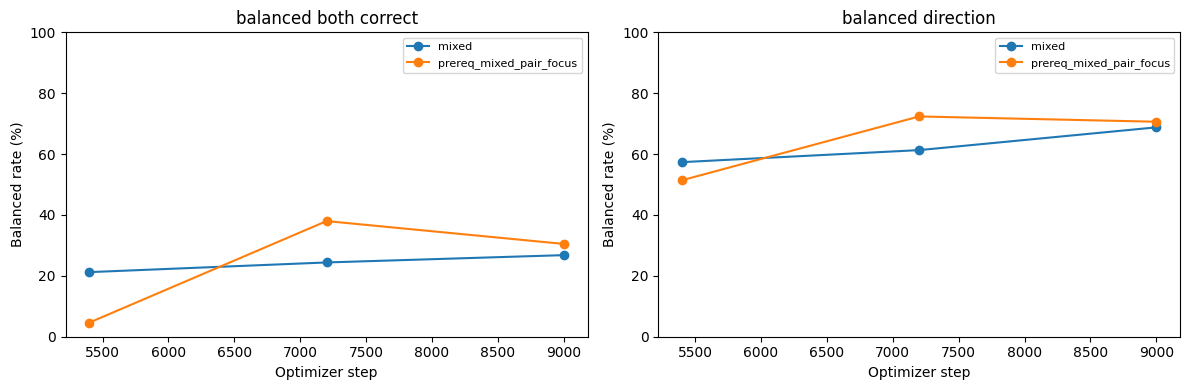

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,2,figsize=(12,4))
for k,metric in enumerate(("balanced_both_correct","balanced_direction")):
    for schedule,g in summary.groupby("schedule"):
        means=g.groupby("step")[metric].mean()
        axes[k].plot(means.index, 100*means.values, marker="o", label=schedule)
    axes[k].set(xlabel="Optimizer step",ylabel="Balanced rate (%)",title=metric.replace("_"," "))
    axes[k].set_ylim(0,100)
    axes[k].legend(fontsize=8)
fig.tight_layout()
fig.savefig(folder/"swap_trajectories.png",dpi=180)
plt.show()

## Interpretation guardrails

A positive effect during Pair focus supports *association-sensitive predictions*, not internal symbolic object binding. The same 109 questions are reused at every checkpoint. Stage differences are paired within seed; seed intervals are exploratory, unadjusted, and include implementation nondeterminism. Check the positive→negative and negative→positive columns before interpreting an aggregate score.